# DCC, ADCC and copulas : how well do they approximate the realised correlation ?

**Question.** Same study as `constant_correlation.ipynb` and `ewma_correlation.ipynb` (20 baskets of two or three
Euronext Paris stocks, horizons 1 month to 5 years, one window every 21 days after 2 years of history), with
conditional correlation models of increasing richness (`dcc_correlation.py`) :

| model | marginals | dependence |
|---|---|---|
| DCC-GARCH | GARCH(1,1)-t | DCC(1,1), Gaussian quasi-likelihood |
| DCC-GJR | GJR-GARCH(1,1,1)-t (leverage effect) | DCC(1,1) |
| ADCC-GJR | GJR-GARCH-t | asymmetric DCC : the correlation also reacts to joint negative shocks |
| ADCC-GJR, Gaussian copula | GJR-GARCH, empirical distribution of the residuals | ADCC on the normal scores, Gaussian copula likelihood |
| ADCC-GJR, t copula | GJR-GARCH, empirical distribution | ADCC on the t scores, Student-t copula likelihood (ν estimated) |

Q_t = (1 − a − b) Q̄ − g N̄ + a z_{t−1}z'_{t−1} + g n_{t−1}n'_{t−1} + b Q_{t−1}, R_t = corr(Q_t), n = min(z, 0) ;
DCC is g = 0. Unlike the EWMA, the (A)DCC correlation reverts to its long-run level R̄ : the forecast over [t, t + H)
depends on the maturity, R̄ + w(H)(R_t − R̄) with w(H) = (1 − φ^H) / (H (1 − φ)), φ = a + b + g/2
(Engle-Sheppard). The benchmarks are the expanding-window constant and the EWMA of the previous studies, on the same
windows.

**In- and out-of-sample.** In-sample, everything is estimated on the whole history. Out-of-sample, the marginals, the
empirical distributions and the (A)DCC are re-estimated every year on the past only.

**Tests.**
1. Likelihood ratio tests between nested models (in-sample) : GJR against GARCH, ADCC against DCC, t copula against
   Gaussian copula — does each addition fit the daily data better ?
2. RMSE, noise floor and excess RMSE, as for the EWMA — does it forecast the correlation over the product's life better ?
3. Diebold-Mariano, against the constant and against the previous model of the list.
4. Mincer-Zarnowitz (realised = a + b · forecast, b = 1 for an unbiased forecast).
5. Monte Carlo test of each fitted model, as in the constant study : since the (A)DCC is stationary it can serve as
   H0 (200 simulations per basket and model, two-sided p-values).

As before, Newey-West p-values are optimistic at the long horizons (≈ 4 independent windows at 5 years) and the
20 baskets are corrected by Benjamini-Hochberg.

In [1]:
import os, sys, pickle, warnings
from concurrent.futures import ProcessPoolExecutor
sys.path.append(os.path.abspath("."))                                   # Models/Correlation
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import constant_correlation as cc
import dcc_correlation as dc

pd.set_option("display.float_format", lambda x: f"{x:.4g}")
DATA = os.path.join("..", "..", "Data", "Equity")
HORIZONS, MODELS = cc.HORIZONS, list(dc.MODELS)
ALL = ["constant", "EWMA"] + MODELS
COLORS = {"constant": "#52514e", "EWMA": "#eb6834", "DCC-GARCH": "#2a78d6", "DCC-GJR": "#1baf7a", "ADCC-GJR": "#eda100",
          "ADCC-GJR, Gaussian copula": "#e87ba4", "ADCC-GJR, t copula": "#6250d6"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.figsize": (11, 4), "lines.linewidth": 1.2})

## 1. Estimation

About 1.5 minute per basket (the yearly re-estimations of the t copula dominate), run in parallel ; the results are
cached in `dcc_results.pkl` (set `RECOMPUTE = True` after a data refresh).

In [2]:
px = pd.read_csv(os.path.join(DATA, "Universe_Daily_AdjClose.csv"), index_col="Date", parse_dates=True)
CACHE, RECOMPUTE = "dcc_results.pkl", False
if RECOMPUTE or not os.path.exists(CACHE):
    with ProcessPoolExecutor(max_workers=os.cpu_count()) as ex:
        results = dict(ex.map(dc.analyse_named, [(name, px, {}) for name in cc.BASKETS]))
    results = {name: results[name] for name in cc.BASKETS}
    with open(CACHE, "wb") as f:
        pickle.dump(results, f)
with open(CACHE, "rb") as f:
    results = pickle.load(f)

T = pd.concat({k: v["table"] for k, v in results.items()}, names=["basket"]).reset_index(level=0)
MC = pd.concat({k: v["mc"] for k, v in results.items()}, names=["basket"]).reset_index(level=0)

def per_model(df, column, agg="median"):
    """ model x horizon table of a column aggregated over the baskets. """
    return df.pivot_table(index="model", columns="horizon", values=column, aggfunc=agg)[list(HORIZONS)].reindex(
        [m for m in ALL if m in set(df.model)])

print(len(results), "baskets")

20 baskets


## 2. Estimated parameters

In [3]:
P = pd.concat({k: v["params"] for k, v in results.items()}, names=["basket", "model"]).reset_index()
P[["a", "g", "b", "nu", "phi", "half-life (days)"]] = P[["a", "g", "b", "nu", "phi", "half-life (days)"]].astype(float)
display(P.groupby("model", sort=False)[["a", "g", "b", "nu", "phi", "half-life (days)"]].median()
        .style.format("{:.4g}").set_caption("Median over the 20 baskets (in-sample)"))
G = pd.concat({k: v["gjr"] for k, v in results.items()}, names=["basket", "stock"]).reset_index()
G = G.drop_duplicates("stock").set_index("stock")[["alpha[1]", "gamma[1]", "beta[1]", "nu"]]
G.style.format("{:.3f}").set_caption("GJR-GARCH-t parameters per stock (gamma : extra reaction to negative returns)")

,a,g,b,nu,phi,half-life (days)
model,,,,,,
DCC-GARCH,0.01327,0,0.9794,nan,0.9933,102.4
DCC-GJR,0.01637,0,0.9749,nan,0.9914,79.96
ADCC-GJR,0.008389,0.0225,0.9692,nan,0.9912,78.03
"ADCC-GJR, Gaussian copula",0.01432,0.02885,0.9645,nan,0.9921,87.12
"ADCC-GJR, t copula",0.01569,0.02195,0.9686,7.903,0.9947,130.4


,alpha[1],gamma[1],beta[1],nu
stock,,,,
LVMH,0.000,0.090,0.945,5.573
HERMES,0.034,0.032,0.945,5.118
KERING,0.004,0.053,0.968,4.488
BNP,0.014,0.109,0.919,6.647
SOCGEN,0.038,0.084,0.915,5.249
CREDITAGRICOLE,0.023,0.070,0.936,5.431
AIRBUS,0.019,0.085,0.924,5.550
SAFRAN,0.026,0.103,0.913,5.251
THALES,0.024,0.070,0.931,4.723


## 3. Likelihood ratio tests (in-sample, daily fit)

- **GJR vs GARCH** : sum over the stocks of the basket of 2 (LL_GJR − LL_GARCH), χ²(number of stocks).
- **ADCC vs DCC** (on the same GJR residuals) : g = 0 is on the boundary, p-value of the ½χ²(0) + ½χ²(1) mixture.
- **t vs Gaussian copula** (ADCC-GJR, same empirical marginals) : 1/ν = 0 on the boundary, same mixture.

In [4]:
LR = pd.concat({k: v["lr"] for k, v in results.items()}, names=["basket", "test"]).reset_index()
lr_p = LR.pivot(index="basket", columns="test", values="p-value").reindex(list(cc.BASKETS))
lr_s = LR.pivot(index="basket", columns="test", values="LR").reindex(list(cc.BASKETS))
display(lr_s.style.format("{:.1f}").set_caption("LR statistic"))
pd.DataFrame({"median LR": lr_s.median(), "max p-value": lr_p.max(),
              "rejected (BH, 5 %)": lr_p.apply(lambda p: (cc.benjamini_hochberg(p) < 0.05).sum())}).T

test,ADCC vs DCC (g = 0),"GJR vs GARCH (marginals, sum)",t vs Gaussian copula (1/nu = 0)
basket,,,
LVMH / Hermès,2.0,132.1,149.2
LVMH / Kering,85.1,190.9,153.9
LVMH / Hermès / Kering,85.3,204.9,338.0
BNP / SocGen,176.1,131.2,471.9
BNP / SocGen / Crédit Agricole,190.7,182.6,899.9
Airbus / Safran,3.8,122.5,154.9
Airbus / Safran / Thales,20.7,163.9,323.4
L'Oréal / Danone,-0.0,85.7,171.9
L'Oréal / Pernod,3.8,64.0,78.0


test,ADCC vs DCC (g = 0),"GJR vs GARCH (marginals, sum)",t vs Gaussian copula (1/nu = 0)
median LR,17.73,130.5,163.4
max p-value,0.5,8.765e-07,5.37e-18
"rejected (BH, 5 %)",16,20,20


## 4. RMSE against the realised correlation (out-of-sample)

In [5]:
display(per_model(T, "rmse oos").style.format("{:.3f}").background_gradient(cmap="Blues", axis=0)
        .set_caption("Median out-of-sample RMSE over the 20 baskets"))
display(per_model(T[T.model.isin(MODELS)], "rmse is").style.format("{:.3f}")
        .set_caption("Median in-sample RMSE (parameters estimated on the whole history)"))
floor = T[T.model == "constant"].groupby("horizon")["noise floor"].median()[list(HORIZONS)]
display(per_model(T, "excess oos").style.format("{:.3f}").background_gradient(cmap="Blues", axis=0)
        .set_caption(f"Median excess RMSE (noise floor : {', '.join(f'{h} {v:.3f}' for h, v in floor.items())})"))

horizon,1m,2m,3m,6m,1y,2y,3y,5y
model,,,,,,,,
constant,0.247,0.202,0.186,0.163,0.151,0.145,0.143,0.142
EWMA,0.225,0.182,0.169,0.156,0.148,0.144,0.141,0.148
DCC-GARCH,0.232,0.190,0.178,0.163,0.153,0.148,0.151,0.144
DCC-GJR,0.234,0.193,0.179,0.167,0.160,0.153,0.153,0.146
ADCC-GJR,0.238,0.198,0.186,0.171,0.160,0.159,0.155,0.146
"ADCC-GJR, Gaussian copula",0.227,0.186,0.170,0.154,0.142,0.137,0.140,0.137
"ADCC-GJR, t copula",0.229,0.187,0.171,0.157,0.144,0.140,0.144,0.140


horizon,1m,2m,3m,6m,1y,2y,3y,5y
model,,,,,,,,
DCC-GARCH,0.218,0.174,0.158,0.139,0.124,0.111,0.112,0.103
DCC-GJR,0.218,0.176,0.160,0.141,0.126,0.114,0.115,0.109
ADCC-GJR,0.219,0.177,0.161,0.144,0.127,0.117,0.117,0.113
"ADCC-GJR, Gaussian copula",0.215,0.174,0.159,0.142,0.122,0.106,0.109,0.099
"ADCC-GJR, t copula",0.218,0.176,0.160,0.144,0.122,0.111,0.115,0.106


horizon,1m,2m,3m,6m,1y,2y,3y,5y
model,,,,,,,,
constant,0.140,0.138,0.141,0.133,0.136,0.136,0.137,0.137
EWMA,0.116,0.109,0.114,0.124,0.128,0.135,0.135,0.144
DCC-GARCH,0.118,0.123,0.128,0.133,0.137,0.139,0.145,0.140
DCC-GJR,0.120,0.129,0.135,0.140,0.144,0.144,0.148,0.141
ADCC-GJR,0.128,0.134,0.139,0.143,0.144,0.151,0.149,0.142
"ADCC-GJR, Gaussian copula",0.109,0.117,0.120,0.122,0.126,0.127,0.134,0.132
"ADCC-GJR, t copula",0.114,0.118,0.124,0.125,0.128,0.132,0.138,0.135


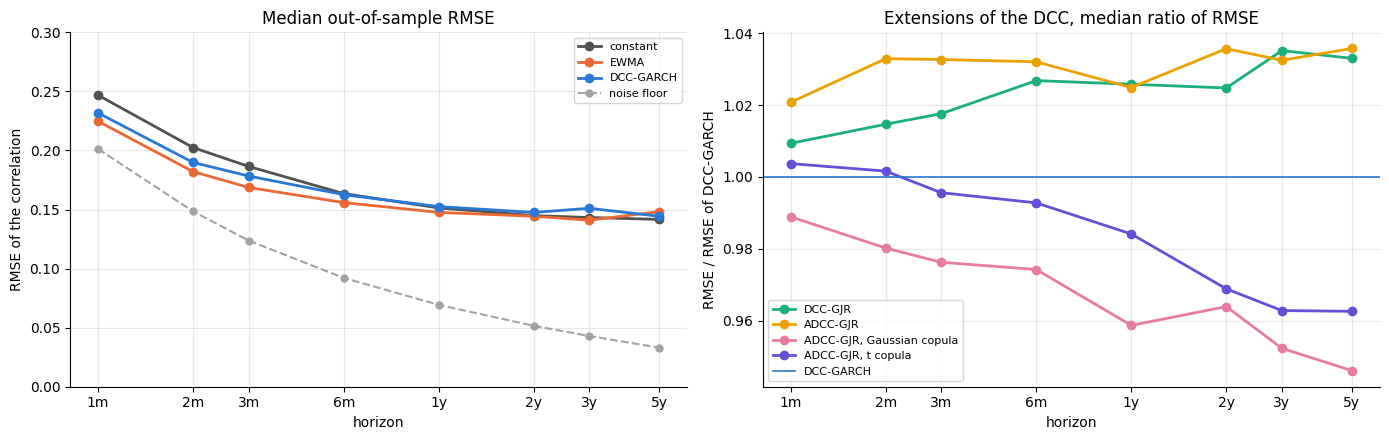

In [6]:
x = np.array(list(HORIZONS.values())) / 252
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for m in ["constant", "EWMA", "DCC-GARCH"]:
    ax[0].plot(x, per_model(T, "rmse oos").loc[m], "o-", color=COLORS[m], lw=2, ms=6, label=m)
ax[0].plot(x, floor, "o--", color="#a3a29d", lw=1.5, ms=5, label="noise floor")
ax[0].set_ylim(0, 0.3); ax[0].set_ylabel("RMSE of the correlation")
ax[0].set_title("Median out-of-sample RMSE")
# ratio of each extension to DCC-GARCH, basket by basket, median
base = T[T.model == "DCC-GARCH"].set_index(["basket", "horizon"])["rmse oos"]
for m in MODELS[1:]:
    ratio = (T[T.model == m].set_index(["basket", "horizon"])["rmse oos"] / base).groupby("horizon").median()
    ax[1].plot(x, ratio[list(HORIZONS)], "o-", color=COLORS[m], lw=2, ms=6, label=m)
ax[1].axhline(1, color=COLORS["DCC-GARCH"], lw=1.2, label="DCC-GARCH")
ax[1].set_ylabel("RMSE / RMSE of DCC-GARCH"); ax[1].set_title("Extensions of the DCC, median ratio of RMSE")
for a in ax:
    a.set_xscale("log"); a.set_xticks(x); a.set_xticklabels(list(HORIZONS)); a.minorticks_off(); a.set_xlabel("horizon")
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Diebold-Mariano tests

Number of baskets (out of 20) where the model is significantly better / worse at 5 % after Benjamini-Hochberg,
against the constant, then against the previous model of the list (each extension against the one it extends).

In [7]:
def dm_counts(stat, pval):
    rows = {}
    for (m, h), g in T.dropna(subset=[pval]).groupby(["model", "horizon"]):
        rej = cc.benjamini_hochberg(g[pval].values) < 0.05
        rows[(m, h)] = f"{int((rej & (g[stat] < 0)).sum())} / {int((rej & (g[stat] > 0)).sum())}"
    return pd.Series(rows).unstack()[list(HORIZONS)]

display(dm_counts("DM vs constant", "DM vs constant p").reindex(ALL[1:]).style.set_caption(
    "Against the expanding-window constant : significantly better / significantly worse"))
prev = T.dropna(subset=["previous"]).groupby("model")["previous"].first()
dm_prev = dm_counts("DM vs previous", "DM vs previous p").reindex(MODELS)
dm_prev.index = [f"{m}  vs  {prev[m]}" for m in dm_prev.index]
dm_prev.style.set_caption("Against the previous model : significantly better / significantly worse")

,1m,2m,3m,6m,1y,2y,3y,5y
EWMA,11 / 0,8 / 0,5 / 0,5 / 0,1 / 1,0 / 2,0 / 2,0 / 4
DCC-GARCH,9 / 2,9 / 2,10 / 2,5 / 3,0 / 2,0 / 3,0 / 7,0 / 7
DCC-GJR,10 / 3,10 / 5,8 / 4,4 / 5,0 / 4,0 / 6,0 / 7,0 / 7
ADCC-GJR,8 / 2,7 / 3,5 / 3,2 / 3,0 / 4,0 / 6,0 / 7,0 / 7
"ADCC-GJR, Gaussian copula",12 / 1,11 / 1,10 / 1,6 / 1,0 / 0,0 / 0,0 / 0,1 / 3
"ADCC-GJR, t copula",13 / 1,11 / 1,10 / 1,7 / 2,1 / 2,0 / 3,0 / 4,0 / 4


,1m,2m,3m,6m,1y,2y,3y,5y
DCC-GARCH vs EWMA,0 / 4,0 / 4,0 / 3,0 / 3,0 / 0,0 / 0,0 / 0,0 / 0
DCC-GJR vs DCC-GARCH,1 / 8,1 / 10,1 / 10,1 / 8,1 / 7,0 / 7,0 / 8,0 / 7
ADCC-GJR vs DCC-GJR,0 / 0,0 / 0,0 / 0,0 / 0,0 / 1,0 / 0,0 / 0,0 / 0
"ADCC-GJR, Gaussian copula vs ADCC-GJR",15 / 0,16 / 0,12 / 0,14 / 0,12 / 0,9 / 0,10 / 0,10 / 0
"ADCC-GJR, t copula vs ADCC-GJR, Gaussian copula",1 / 8,3 / 8,2 / 7,2 / 9,1 / 7,0 / 5,0 / 6,0 / 6


## 6. Mincer-Zarnowitz : unbiasedness of the forecasts

realised = a + b · forecast. b = 1 : the forecast moves as much as the realised correlation ; b < 1 : it
over-reacts.

In [8]:
display(per_model(T[T.model != "constant"], "MZ b").style.format("{:.2f}")
        .background_gradient(cmap="Blues_r", axis=None, vmin=0, vmax=1).set_caption("Median slope b"))
mz_rej = {}
for (m, h), g in T.dropna(subset=["MZ p-value"]).groupby(["model", "horizon"]):
    mz_rej[(m, h)] = int((cc.benjamini_hochberg(g["MZ p-value"].values) < 0.05).sum())
pd.Series(mz_rej).unstack()[list(HORIZONS)].reindex(ALL[1:]).style.set_caption(
    "Number of baskets where (a, b) = (0, 1) is rejected (BH, 5 %)")

horizon,1m,2m,3m,6m,1y,2y,3y,5y
model,,,,,,,,
EWMA,0.65,0.63,0.62,0.58,0.47,0.35,0.30,0.22
DCC-GARCH,0.72,0.72,0.73,0.68,0.39,0.28,0.21,0.16
DCC-GJR,0.73,0.72,0.73,0.71,0.32,0.26,0.15,0.17
ADCC-GJR,0.74,0.73,0.73,0.65,0.34,0.27,0.12,0.17
"ADCC-GJR, Gaussian copula",0.85,0.76,0.78,0.73,0.63,0.32,0.24,0.15
"ADCC-GJR, t copula",0.86,0.80,0.81,0.75,0.47,0.28,0.21,0.13


,1m,2m,3m,6m,1y,2y,3y,5y
EWMA,18,18,18,17,18,19,19,20
DCC-GARCH,15,13,14,14,12,15,16,19
DCC-GJR,14,14,14,14,12,15,16,19
ADCC-GJR,14,14,13,13,14,15,16,19
"ADCC-GJR, Gaussian copula",8,11,11,12,11,13,16,19
"ADCC-GJR, t copula",10,11,11,12,13,14,16,19


## 7. Monte Carlo test : is the realised correlation consistent with the fitted model ?

As in the constant study, with H0 "the fitted model generates the data" : simulated shocks with the model's
dynamics (whitened innovations resampled i.i.d., or drawn from the copula and mapped to the empirical marginals),
observed volatilities. Statistics : in-sample RMSE of the model's forecast, and Fisher statistic between realised and
forecast correlations on non-overlapping windows. Number of baskets rejected (BH, 5 %, two-sided) :

In [9]:
for col, name in [("rmse p MC", "RMSE"), ("Q p MC", "Fisher statistic")]:
    rej = {}
    for (m, h), g in MC.groupby(["model", "horizon"]):
        rej[(m, h)] = int((cc.benjamini_hochberg(g[col].values) < 0.05).sum())
    display(pd.Series(rej).unstack()[list(HORIZONS)].reindex(MODELS).style.set_caption(f"{name} : baskets rejected"))
(MC.assign(ratio=MC["rmse"] / MC["rmse H0 median"]).pivot_table(index="model", columns="horizon", values="ratio",
    aggfunc="median")[list(HORIZONS)].reindex(MODELS).style.format("{:.2f}")
    .set_caption("Median of observed RMSE / median RMSE under H0"))

,1m,2m,3m,6m,1y,2y,3y,5y
DCC-GARCH,0,0,0,0,0,0,0,0
DCC-GJR,0,0,0,0,0,0,0,0
ADCC-GJR,0,0,0,0,0,0,0,0
"ADCC-GJR, Gaussian copula",4,0,0,0,0,0,0,0
"ADCC-GJR, t copula",0,0,0,0,0,0,0,0


,1m,2m,3m,6m,1y,2y,3y,5y
DCC-GARCH,7,5,0,0,0,0,0,0
DCC-GJR,7,5,0,0,0,0,0,0
ADCC-GJR,4,0,0,0,0,0,4,5
"ADCC-GJR, Gaussian copula",20,20,17,12,6,4,0,0
"ADCC-GJR, t copula",0,0,0,0,0,0,4,0


horizon,1m,2m,3m,6m,1y,2y,3y,5y
model,,,,,,,,
DCC-GARCH,1.05,1.04,1.02,1.02,1.04,1.12,1.14,1.30
DCC-GJR,1.05,1.02,0.99,1.01,1.05,1.13,1.23,1.40
ADCC-GJR,1.04,1.02,0.99,1.01,1.03,1.11,1.23,1.45
"ADCC-GJR, Gaussian copula",1.09,1.08,1.06,1.05,1.04,1.06,1.03,1.03
"ADCC-GJR, t copula",0.95,0.92,0.90,0.84,0.84,0.84,0.89,0.96


## 8. Conclusions

**Each extension fits the daily data better…** The likelihood ratio tests reject GARCH against GJR for 20 baskets out
of 20 (median LR 131 : negative returns raise volatility more, γ ≈ 0.03-0.18), DCC against ADCC for 16 out of 20
(the correlation rises after joint falls ; not for L'Oréal / Danone, Sanofi / BNP, LVMH / Hermès…), and the Gaussian
copula against the t copula for 20 out of 20 (ν ≈ 8 : joint extreme moves are more frequent than Gaussian).

**…but most do not forecast the correlation over the life of the product better.** Out-of-sample :
- **DCC-GARCH** beats the constant up to 3 months (9-10 baskets out of 20) but not the EWMA (significantly worse
  for 3-4 baskets), and is worse than the constant beyond 2 years for 7 baskets. Its mean reversion does not help
  at long horizons : the long-run level R̄ it reverts to is itself the moving historical average.
- **GJR marginals** make the forecast worse (significantly for 7-10 baskets at every horizon), and **ADCC** brings
  nothing over DCC (no significant difference). The asymmetries matter for the daily dynamics, not for the
  average correlation over months or years of daily returns.
- **The copula** is the one extension that helps : the ADCC on the normal scores of the empirical marginals is
  significantly better than the ADCC on the GARCH residuals for 9-16 baskets at every horizon, and has the lowest
  median RMSE from 6 months on (0.142 at 1 year against 0.151 for the constant, 0.148 for the EWMA). Using ranks makes
  the correlation dynamics robust to the extreme returns that otherwise dominate the cross products.
- **The t copula** forecasts slightly worse than the Gaussian one (significantly for 5-9 baskets) : its correlation
  parameter is the correlation of the t scores, not the Pearson correlation of returns being forecast.

**Remaining error.** Whatever the model, the excess RMSE stays at 0.11-0.14 : the best model removes about 0.01-0.03
of the 0.14 of the constant at short horizons and almost nothing beyond 2 years. The Mincer-Zarnowitz slope is
better than the EWMA's at short horizons (0.72-0.86 against 0.65 at 1 month) but falls to 0.13-0.17 at 5 years :
no model anticipates the slow level shifts of the correlation.

**Consistency with the models (Monte Carlo).** Unlike the constant (rejected for nearly every basket), the (A)DCC
models are not rejected by the RMSE test, and the Fisher test only at 1-2 months for a quarter to a third of the
baskets : the variability of the realised correlation is compatible with their dynamics. The Gaussian copula
version is rejected by the Fisher test for 20 baskets out of 20 at 1-2 months : with Gaussian joint tails it
underestimates how noisy a one-month realised correlation is. The t copula is never rejected at short horizons
(observed RMSE ≈ 0.85-0.95 of its H0 median) : it is the only model that reproduces both the level and the
dispersion of the realised correlations.

**Consequence for pricing.** For the correlation *level* of a worst-of / best-of, an ADCC on copula scores is the
best forecast (better than the constant up to 6 months, never significantly worse up to 3 years), but its gain is
small next to the ±0.13-0.14 uncertainty that remains at 1-5 years. For the *distribution* of the joint moves, which
drives a worst-of beyond its correlation, the t copula is clearly preferred (likelihood and Monte Carlo tests) : a
natural choice is the correlation level of the Gaussian-copula ADCC with the tail dependence of a t copula
(ν ≈ 8).